# 🚗 RoadVision DUET — RT-DETR Baseline

Public - 0.52443

**Strategy:** COCO-pretrained RT-DETR-X → Bangladesh Fine-tuning → TTA Inference → Submission

This notebook reuses the same data prep / split / yaml pipeline as the YOLOv11 notebook, but swaps the detector to **RT-DETR (Ultralytics implementation)** to get a fast, comparable baseline score.

**Why Ultralytics RT-DETR (not the official RT-DETRv2/HF version) for this baseline:**
- Drop-in replacement for the YOLO training/inference code you already have (same `.train()`, `.val()`, `.predict()` API, same data format).
- Official RT-DETRv2 (HuggingFace `transformers`) needs a different data pipeline (COCO JSON, custom `Trainer`), which is a bigger lift and risks not finishing in a Kaggle session.
- This gets a real, comparable mAP number first; we can move to true RT-DETRv2 afterward if it's worth chasing the extra points.

**Known differences from the YOLO pipeline (read before running):**
- RT-DETR does **not** support `mosaic`, `copy_paste`, `multi_scale`, or `dropout` train args — they're omitted below (Ultralytics will warn/ignore if you add them back).
- RT-DETR is heavier per-image than YOLO at the same `imgsz` → smaller batch size used.
- **No SAHI tiling** — SAHI's `ultralytics` backend is built around YOLO's decoupled head; correctness with RT-DETR's query-based decoder isn't guaranteed. Inference here uses Ultralytics' native TTA (multi-scale + flip) instead, same as the YOLO notebook's Cell 14 fallback.


## 📦 Cell 1 — Install Dependencies

In [1]:
!pip install -q ultralytics ensemble-boxes

import os, shutil, random, json, glob, warnings
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import torch
from ultralytics import RTDETR

warnings.filterwarnings('ignore')

print(f'PyTorch: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 27.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 104.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.2

## ⚙️ Cell 2 — Config (All Paths & Hyperparameters in One Place)

In [2]:
# ============================================================
#  PATHS
# ============================================================
TRAIN_IMAGES_DIR = Path('/kaggle/input/competitions/road-vision/RoadVision_DUET/train/images')
TRAIN_CSV        = Path('/kaggle/input/competitions/road-vision/RoadVision_DUET/train/train.csv')
TEST_IMAGES_DIR  = Path('/kaggle/input/competitions/road-vision/RoadVision_DUET/test/images')
WORK_DIR         = Path('/kaggle/working')
DATASET_DIR      = WORK_DIR / 'dataset'
MODELS_DIR       = WORK_DIR / 'models'
SUBMISSION_DIR   = WORK_DIR / 'submission'

for d in [DATASET_DIR, MODELS_DIR, SUBMISSION_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ============================================================
#  CLASSES
# ============================================================
CLASS_NAMES = [
    'Rickshaw',    # 0
    'Motorcycle',  # 1
    'Tempu',       # 2
    'Sedan Car',   # 3
    'Pickup',      # 4
    'Microbus',    # 5
    'Mini Bus',    # 6
    'Mini Truck',  # 7
    'Agro Use',    # 8
    'Medium Truck',# 9
    'Large Bus',   # 10
    'Heavy Truck', # 11
    'Trailer',     # 12
]
NUM_CLASSES = len(CLASS_NAMES)

# ============================================================
#  HYPERPARAMETERS
# ============================================================
FINETUNE_EPOCHS  = 150      # Fine-tuning on Bangladesh data
IMG_SIZE         = 960      # RT-DETR is heavier than YOLO at same res; keep moderate
VAL_SPLIT        = 0.15     # 15% validation
RANDOM_SEED      = 42
CONF_THRESH      = 0.001    # Very low — NMS will clean up
IOU_THRESH       = 0.5

print('✅ Config loaded.')
print(f'   Classes  : {NUM_CLASSES}')
print(f'   Image sz : {IMG_SIZE}')
print(f'   Finetune : {FINETUNE_EPOCHS} epochs')


✅ Config loaded.
   Classes  : 13
   Image sz : 960
   Finetune : 150 epochs


## 📊 Cell 3 — EDA & Class Distribution

Total annotations : 10475
Unique images     : 810
Classes present   : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]



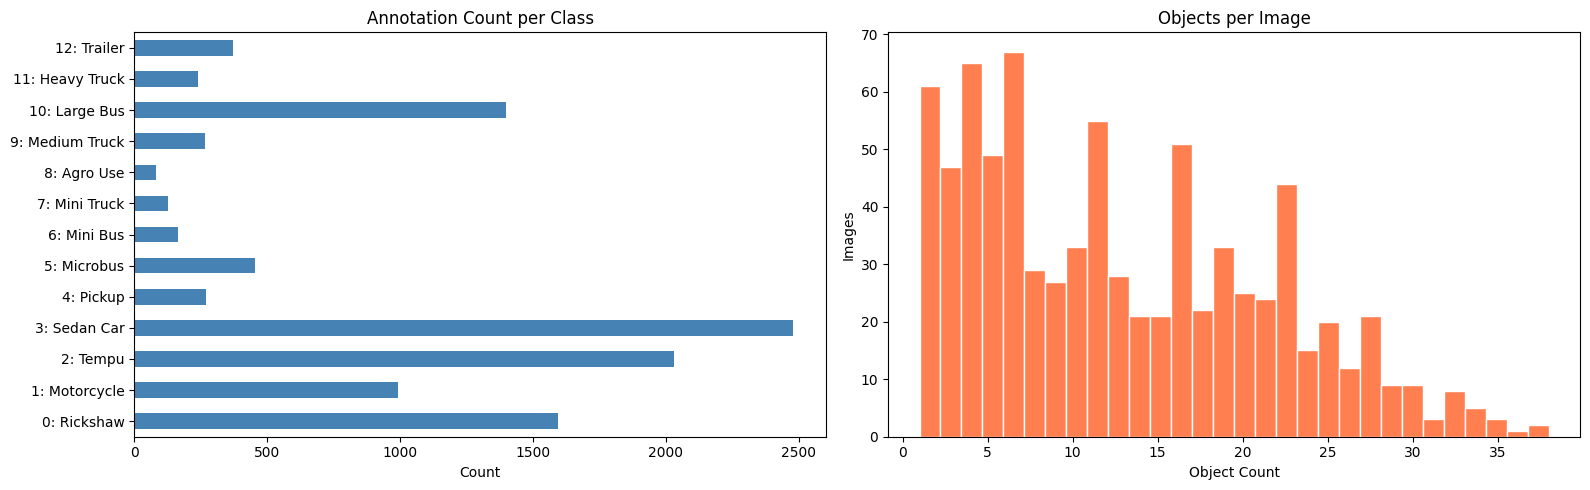


Class counts:
0: Rickshaw        1594
1: Motorcycle       993
2: Tempu           2032
3: Sedan Car       2480
4: Pickup           270
5: Microbus         455
6: Mini Bus         164
7: Mini Truck       127
8: Agro Use          83
9: Medium Truck     265
10: Large Bus      1401
11: Heavy Truck     239
12: Trailer         372


In [3]:
df = pd.read_csv(TRAIN_CSV)
print(f'Total annotations : {len(df)}')
print(f'Unique images     : {df["image_id"].nunique()}')
print(f'Classes present   : {sorted(df["class_id"].unique())}\n')

# Class distribution
class_counts = df['class_id'].value_counts().sort_index()
class_counts.index = [f'{i}: {CLASS_NAMES[i]}' for i in class_counts.index]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

class_counts.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Annotation Count per Class')
axes[0].set_xlabel('Count')

objs_per_img = df.groupby('image_id').size()
axes[1].hist(objs_per_img, bins=30, color='coral', edgecolor='white')
axes[1].set_title('Objects per Image')
axes[1].set_xlabel('Object Count')
axes[1].set_ylabel('Images')

plt.tight_layout()
plt.savefig(WORK_DIR / 'eda_distribution.png', dpi=120, bbox_inches='tight')
plt.show()
print('\nClass counts:')
print(class_counts.to_string())


## 🗂️ Cell 4 — Stratified Train/Val Split & YOLO-format Label Creation\n\n_(RT-DETR in Ultralytics consumes the same YOLO-format dataset structure, so this cell is unchanged from the original pipeline.)_

In [4]:
img_dominant = (
    df.groupby('image_id')['class_id']
      .agg(lambda x: x.mode()[0])
      .reset_index()
)

class_img_counts = img_dominant['class_id'].value_counts()
print('Images per dominant class:')
for cls, cnt in class_img_counts.sort_index().items():
    flag = '⚠️ (too rare to stratify)' if cnt < 2 else ''
    print(f'  Class {cls:2d} ({CLASS_NAMES[cls]:<15}): {cnt:4d} images {flag}')

rare_classes   = set(class_img_counts[class_img_counts < 2].index)
rare_mask      = img_dominant['class_id'].isin(rare_classes)
rare_df        = img_dominant[rare_mask]
stratify_df    = img_dominant[~rare_mask]

print(f'\nImages always in train (rare classes): {len(rare_df)}')
print(f'Images for stratified split          : {len(stratify_df)}')

if len(stratify_df) > 0:
    strat_train_ids, strat_val_ids = train_test_split(
        stratify_df['image_id'],
        test_size=VAL_SPLIT,
        stratify=stratify_df['class_id'],
        random_state=RANDOM_SEED
    )
else:
    strat_train_ids, strat_val_ids = stratify_df['image_id'], pd.Series([], dtype=str)

train_ids = set(strat_train_ids) | set(rare_df['image_id'])
val_ids   = set(strat_val_ids)

print(f'\nFinal split:')
print(f'  Train images : {len(train_ids)}')
print(f'  Val images   : {len(val_ids)}')

for split in ['train', 'val']:
    (DATASET_DIR / split / 'images').mkdir(parents=True, exist_ok=True)
    (DATASET_DIR / split / 'labels').mkdir(parents=True, exist_ok=True)

def write_labels(image_id, split):
    """Copy image and write YOLO-format label file."""
    image_id_stem = Path(image_id).stem

    img_path = None
    for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']:
        candidate = TRAIN_IMAGES_DIR / f'{image_id_stem}{ext}'
        if candidate.exists():
            img_path = candidate
            break
    if img_path is None:
        print(f'⚠️  Image not found: {image_id_stem}')
        return

    dst_img = DATASET_DIR / split / 'images' / img_path.name
    shutil.copy2(img_path, dst_img)

    rows = df[df['image_id'].apply(lambda x: Path(x).stem) == image_id_stem]
    label_path = DATASET_DIR / split / 'labels' / (img_path.stem + '.txt')
    with open(label_path, 'w') as f:
        for _, row in rows.iterrows():
            f.write(f"{int(row['class_id'])} {row['x_center']:.6f} {row['y_center']:.6f} {row['width']:.6f} {row['height']:.6f}\n")

for image_id in train_ids:
    write_labels(image_id, 'train')
for image_id in val_ids:
    write_labels(image_id, 'val')

print('\n✅ Dataset directory built.')
print(f'   Train images : {len(list((DATASET_DIR / "train" / "images").glob("*")))}')
print(f'   Val images   : {len(list((DATASET_DIR / "val" / "images").glob("*")))}')


Images per dominant class:
  Class  0 (Rickshaw       ):  160 images 
  Class  1 (Motorcycle     ):   67 images 
  Class  2 (Tempu          ):  221 images 
  Class  3 (Sedan Car      ):  215 images 
  Class  4 (Pickup         ):    2 images 
  Class  5 (Microbus       ):   13 images 
  Class  6 (Mini Bus       ):    1 images ⚠️ (too rare to stratify)
  Class  8 (Agro Use       ):    3 images 
  Class  9 (Medium Truck   ):    3 images 
  Class 10 (Large Bus      ):   46 images 
  Class 11 (Heavy Truck    ):    6 images 
  Class 12 (Trailer        ):   73 images 

Images always in train (rare classes): 1
Images for stratified split          : 809

Final split:
  Train images : 688
  Val images   : 122

✅ Dataset directory built.
   Train images : 688
   Val images   : 122


## 📝 Cell 5 — Generate dataset.yaml

In [5]:
yaml_content = f"""# RoadVision DUET — Bangladesh Vehicle Detection (RT-DETR baseline)
path: {DATASET_DIR}
train: train/images
val:   val/images

nc: {NUM_CLASSES}
names:
"""
for i, name in enumerate(CLASS_NAMES):
    yaml_content += f'  {i}: {name}\n'

YAML_PATH = WORK_DIR / 'bangladesh.yaml'
with open(YAML_PATH, 'w') as f:
    f.write(yaml_content)

print('✅ bangladesh.yaml created:')
print(yaml_content)


✅ bangladesh.yaml created:
# RoadVision DUET — Bangladesh Vehicle Detection (RT-DETR baseline)
path: /kaggle/working/dataset
train: train/images
val:   val/images

nc: 13
names:
  0: Rickshaw
  1: Motorcycle
  2: Tempu
  3: Sedan Car
  4: Pickup
  5: Microbus
  6: Mini Bus
  7: Mini Truck
  8: Agro Use
  9: Medium Truck
  10: Large Bus
  11: Heavy Truck
  12: Trailer



## 🛰️ Cell 6 — RT-DETR-X Fine-Tuning (Bangladesh)

Notes on the hyperparameters below vs. the YOLO run:
- `mosaic`, `mixup`, `copy_paste`, `multi_scale`, `dropout` removed — not supported by RT-DETR in Ultralytics.
- `batch` lowered (RT-DETR's transformer encoder/decoder uses noticeably more VRAM per sample than YOLO at the same `imgsz`).
- Everything else (optimizer, LR schedule, geometric/color augmentation, loss weighting where applicable) mirrors the original fine-tune config as closely as RT-DETR's trainer supports, so the comparison is as apples-to-apples as possible.


In [6]:
print('='*60)
print('RT-DETR-X — Bangladesh Fine-Tuning (Baseline)')
print('='*60)

model = RTDETR('rtdetr-l.pt')   # COCO-pretrained RT-DETR-X

finetune_results = model.train(
    data=str(YAML_PATH),
    epochs=FINETUNE_EPOCHS,
    imgsz=640,
    batch=16,                    # Conservative — RT-DETR is VRAM-heavy; raise if T4 allows
    patience=30,
    optimizer='AdamW',

    lr0=0.0001,                 # RT-DETR trains best with lower LR than YOLO
    lrf=0.01,
    warmup_epochs=5,
    cos_lr=True,
    weight_decay=0.0001,

    amp=True,
    cache='ram',
    workers=4,

    # ── AUGMENTATION (subset supported by RT-DETR trainer) ──
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    degrees=10.0,
    translate=0.15,
    scale=0.6,
    shear=2.0,
    perspective=0.0005,
    fliplr=0.5,
    flipud=0.1,
    erasing=0.4,
    # ─────────────────────────────────────────────────────────

    save=True,
    save_period=10,
    project=str(MODELS_DIR),
    name='rtdetr_baseline',
    exist_ok=True,
    verbose=True,
    plots=True,
    
)

FINETUNE_BEST = MODELS_DIR / 'rtdetr_baseline' / 'weights' / 'best.pt'
FINETUNE_LAST = MODELS_DIR / 'rtdetr_baseline' / 'weights' / 'last.pt'

print(f'\n✅ Fine-tuning complete.')
print(f'   Best weights : {FINETUNE_BEST}')
print(f'   Last weights : {FINETUNE_LAST}')


RT-DETR-X — Bangladesh Fine-Tuning (Baseline)
Ultralytics 8.4.75 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/bangladesh.yaml, degrees=10.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.1, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtdetr_baseline, nbs=64, nms=False, opset=None, optim

## 📈 Cell 7 — Plot Training Curves

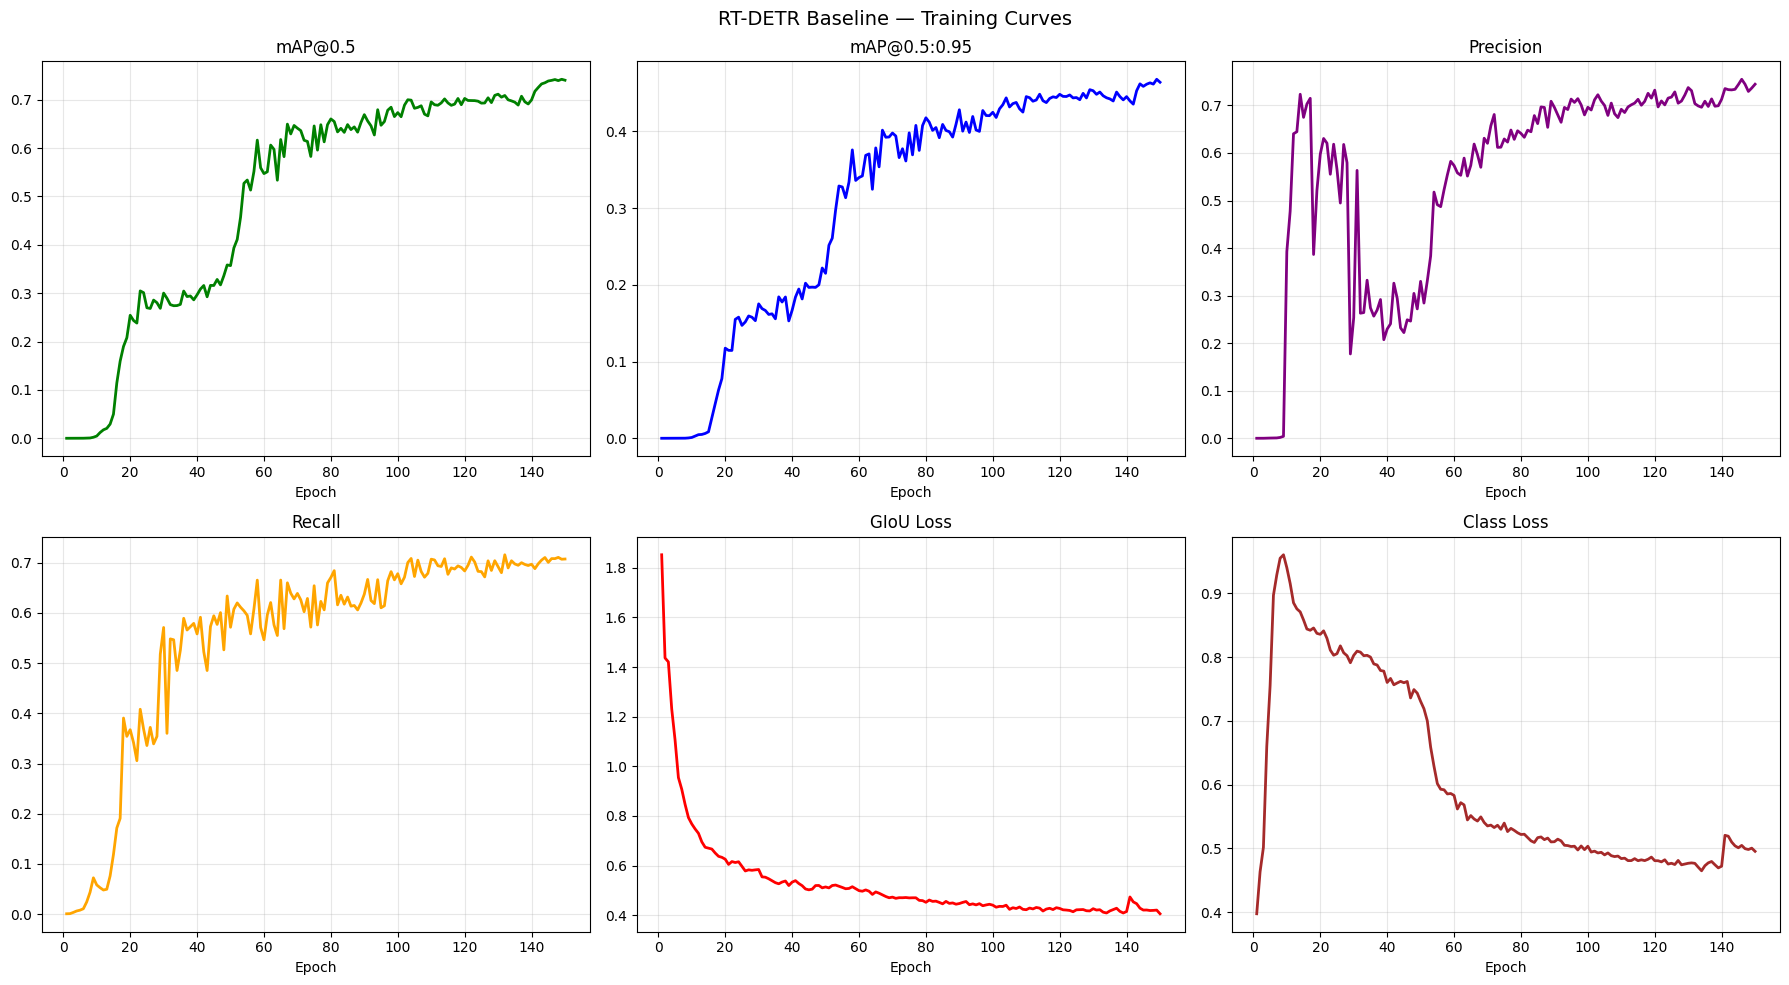


🏆 Best mAP@0.5 : 0.7423 at epoch 149


In [7]:
results_csv = MODELS_DIR / 'rtdetr_baseline' / 'results.csv'

if results_csv.exists():
    res_df = pd.read_csv(results_csv)
    res_df.columns = res_df.columns.str.strip()

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle('RT-DETR Baseline — Training Curves', fontsize=14)

    metrics = [
        ('metrics/mAP50(B)',    'mAP@0.5',      'green',  axes[0,0]),
        ('metrics/mAP50-95(B)', 'mAP@0.5:0.95', 'blue',   axes[0,1]),
        ('metrics/precision(B)','Precision',    'purple', axes[0,2]),
        ('metrics/recall(B)',   'Recall',       'orange', axes[1,0]),
        ('train/giou_loss',     'GIoU Loss',    'red',    axes[1,1]),
        ('train/cls_loss',      'Class Loss',   'brown',  axes[1,2]),
    ]

    for col, label, color, ax in metrics:
        if col in res_df.columns:
            ax.plot(res_df['epoch'], res_df[col], color=color, linewidth=2)
            ax.set_title(label)
            ax.set_xlabel('Epoch')
            ax.grid(True, alpha=0.3)
        else:
            ax.set_title(f'{label} (column not found)')

    plt.tight_layout()
    plt.savefig(WORK_DIR / 'rtdetr_training_curves.png', dpi=120, bbox_inches='tight')
    plt.show()

    best_epoch = res_df['metrics/mAP50(B)'].idxmax()
    best_map   = res_df.loc[best_epoch, 'metrics/mAP50(B)']
    print(f'\n🏆 Best mAP@0.5 : {best_map:.4f} at epoch {int(res_df.loc[best_epoch, "epoch"])}')
else:
    print('results.csv not found — training may still be running or path is different.')


## 🔍 Cell 8 — Validation on Val Set (Best Weights)

In [8]:
print('Running validation with best weights...')
val_model = RTDETR(str(FINETUNE_BEST))

val_metrics = val_model.val(
    data=str(YAML_PATH),
    imgsz=IMG_SIZE,
    batch=4,
    conf=0.001,
    iou=IOU_THRESH,
    verbose=True,
    plots=True,
    save_json=True,
)

print('\n' + '='*50)
print(f'  mAP@0.5      : {val_metrics.box.map50:.4f}')
print(f'  mAP@0.5:0.95 : {val_metrics.box.map:.4f}')
print(f'  Precision    : {val_metrics.box.mp:.4f}')
print(f'  Recall       : {val_metrics.box.mr:.4f}')
print('='*50)

print('\nPer-class AP@0.5:')
if hasattr(val_metrics.box, 'ap50'):
    for i, (name, ap) in enumerate(zip(CLASS_NAMES, val_metrics.box.ap50)):
        bar = '█' * int(ap * 30)
        print(f'  {i:2d} {name:<15} {ap:.3f}  {bar}')

print('\n📌 Compare this mAP@0.5 / mAP@0.5:0.95 directly against your YOLOv11 run')
print('   (same val split, same metrics) to see which architecture wins as the baseline.')


Running validation with best weights...
Ultralytics 8.4.75 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
rt-detr-l summary: 310 layers, 32,010,455 parameters, 0 gradients, 103.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3540.6±1062.2 MB/s, size: 413.7 KB)
val: Scanning /kaggle/working/dataset/val/labels.cache... 122 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 122/122 36.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 2.7it/s 11.5s
                   all        122       1532      0.708      0.722      0.741      0.433
              Rickshaw         51        232      0.682      0.711      0.719       0.32
            Motorcycle         56        155      0.686      0.561      0.629       0.27
                 Tempu         75        283      0.713       0.72       0.76      0.412
             Sedan Car         94        363      0.757      0.826      0.832      0.517
 

## 🔬 Cell 9 — Inference on Test Set (Native Ultralytics TTA — no SAHI)

SAHI is skipped here because its `ultralytics` backend assumes YOLO's anchor-free decoupled head;
RT-DETR's query-based decoder isn't a supported/verified combination. This uses Ultralytics' own
TTA (multi-scale + horizontal flip) at full image resolution instead — same approach as Cell 14
("fallback") in your original YOLO notebook.


In [9]:
print('Running TTA inference with RT-DETR...')
infer_model = RTDETR(str(FINETUNE_BEST))

test_images = sorted(list(TEST_IMAGES_DIR.glob('*.jpg')) +
                     list(TEST_IMAGES_DIR.glob('*.jpeg')) +
                     list(TEST_IMAGES_DIR.glob('*.png')))
print(f'Test images found: {len(test_images)}')

tta_results = infer_model.predict(
    source=str(TEST_IMAGES_DIR),
    imgsz=IMG_SIZE,
    augment=True,           # TTA: multi-scale + flip
    conf=CONF_THRESH,
    iou=IOU_THRESH,
    save=False,
    verbose=False,
    stream=True,
)

all_predictions = {}
for r in tta_results:
    img_id = Path(r.path).stem
    preds  = []

    if r.boxes is not None and len(r.boxes) > 0:
        boxes  = r.boxes.xywhn.cpu().numpy()
        confs  = r.boxes.conf.cpu().numpy()
        clss   = r.boxes.cls.cpu().numpy().astype(int)

        for cls_id, conf, (cx, cy, bw, bh) in zip(clss, confs, boxes):
            preds.append((int(cls_id), float(conf),
                          float(cx), float(cy), float(bw), float(bh)))

    all_predictions[img_id] = preds

total_dets = sum(len(v) for v in all_predictions.values())
print(f'\n✅ RT-DETR inference complete.')
print(f'   Total detections : {total_dets}')
print(f'   Avg per image    : {total_dets / len(test_images):.1f}')


Running TTA inference with RT-DETR...
Test images found: 327

✅ RT-DETR inference complete.
   Total detections : 98100
   Avg per image    : 300.0


## 📄 Cell 10 — Generate Submission CSV

In [10]:
def build_prediction_string(preds):
    """Build space-separated prediction string for submission."""
    if not preds:
        return ''
    parts = []
    for cls_id, conf, cx, cy, bw, bh in sorted(preds, key=lambda x: -x[1]):
        parts.append(f'{cls_id} {conf:.4f} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}')
    return ' '.join(parts)

rows = []
for img_path in sorted(test_images):
    img_id = img_path.stem
    preds  = all_predictions.get(img_id, [])
    rows.append({
        'image_id': img_id,
        'PredictionString': build_prediction_string(preds)
    })

submission_df = pd.DataFrame(rows)

print(f'Submission rows       : {len(submission_df)}')
print(f'Empty predictions     : {(submission_df["PredictionString"] == "").sum()}')
print(f'Non-empty predictions : {(submission_df["PredictionString"] != "").sum()}')
print('\nSample rows:')
print(submission_df.head(3).to_string(index=False))

SUBMISSION_PATH = SUBMISSION_DIR / 'submission_rtdetr_baseline.csv'
submission_df.to_csv(SUBMISSION_PATH, index=False)
print(f'\n✅ Submission saved → {SUBMISSION_PATH}')


Submission rows       : 327
Empty predictions     : 0
Non-empty predictions : 327

Sample rows:
                                     image_id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

## ✅ Cell 11 — Validate Submission Format

In [11]:
def validate_submission(submission_path):
    df_sub = pd.read_csv(submission_path)
    errors = []

    if list(df_sub.columns) != ['image_id', 'PredictionString']:
        errors.append(f'Wrong columns: {list(df_sub.columns)}')

    for _, row in df_sub.iterrows():
        ps = str(row['PredictionString']).strip()
        if ps == '' or ps == 'nan':
            continue
        tokens = ps.split()
        if len(tokens) % 6 != 0:
            errors.append(f"{row['image_id']}: token count {len(tokens)} not divisible by 6")
            continue
        for i in range(0, len(tokens), 6):
            cls_id = int(tokens[i])
            conf   = float(tokens[i+1])
            vals   = [float(x) for x in tokens[i+2:i+6]]
            if not (0 <= cls_id <= 12):
                errors.append(f"{row['image_id']}: invalid class_id {cls_id}")
            if not (0.0 <= conf <= 1.0):
                errors.append(f"{row['image_id']}: conf {conf} out of [0,1]")
            if any(v < 0 or v > 1 for v in vals):
                errors.append(f"{row['image_id']}: bbox values out of [0,1]: {vals}")

    if errors:
        print(f'❌ {len(errors)} errors found:')
        for e in errors[:10]:
            print(f'   {e}')
    else:
        print(f'✅ Submission valid! {len(df_sub)} rows, all format checks passed.')

    non_empty = df_sub[df_sub['PredictionString'].str.strip().fillna('') != '']
    print(f'   Images with detections: {len(non_empty)} / {len(df_sub)}')

validate_submission(SUBMISSION_PATH)


✅ Submission valid! 327 rows, all format checks passed.
   Images with detections: 327 / 327


## 💾 Cell 12 — Save Models & Artifacts

In [12]:
import zipfile

SAVE_PATH = WORK_DIR / 'roadvision_rtdetr_baseline.zip'

files_to_save = [
    (FINETUNE_BEST,  'models/rtdetr_finetune_best.pt'),
    (FINETUNE_LAST,  'models/rtdetr_finetune_last.pt'),
    (YAML_PATH,      'configs/bangladesh.yaml'),
    (SUBMISSION_PATH,'submission/submission_rtdetr_baseline.csv'),
    (WORK_DIR / 'rtdetr_training_curves.png', 'plots/rtdetr_training_curves.png'),
    (WORK_DIR / 'eda_distribution.png','plots/eda_distribution.png'),
]

with zipfile.ZipFile(SAVE_PATH, 'w', zipfile.ZIP_DEFLATED) as zf:
    for src, arcname in files_to_save:
        src = Path(src)
        if src.exists():
            zf.write(src, arcname)
            print(f'  ✅ {arcname}')
        else:
            print(f'  ⚠️  Missing: {src}')

size_mb = SAVE_PATH.stat().st_size / 1e6
print(f'\n📦 Saved → {SAVE_PATH}  ({size_mb:.1f} MB)')
print('\nAll done! 🎉 Submit submission/submission_rtdetr_baseline.csv to the leaderboard.')


  ✅ models/rtdetr_finetune_best.pt
  ✅ models/rtdetr_finetune_last.pt
  ✅ configs/bangladesh.yaml
  ✅ submission/submission_rtdetr_baseline.csv
  ✅ plots/rtdetr_training_curves.png
  ✅ plots/eda_distribution.png

📦 Saved → /kaggle/working/roadvision_rtdetr_baseline.zip  (123.5 MB)

All done! 🎉 Submit submission/submission_rtdetr_baseline.csv to the leaderboard.


---
## 📋 Summary

| Step | Detail |
|---|---|
| Base model | RT-DETR-X (COCO pretrained, Ultralytics implementation) |
| Phase | Direct Bangladesh fine-tuning — 150 epochs, imgsz=960, AdamW, cosine LR |
| Augmentation | HSV, geometric (rotate/translate/scale/shear/perspective), flip, erasing — **no** mosaic/copy-paste/mixup/multi-scale (unsupported by RT-DETR trainer) |
| Inference | Native Ultralytics TTA (multi-scale + flip) — **no SAHI** (unsupported combination with RT-DETR head) |
| Output | `submission/submission_rtdetr_baseline.csv` |

**Submit:** `/kaggle/working/submission/submission_rtdetr_baseline.csv`

**Next steps once you have this baseline number:**
1. Compare RT-DETR-X mAP@0.5 directly against your YOLOv11l fine-tune (same val split → fair comparison).
2. If RT-DETR baseline looks promising, consider the official **RT-DETRv2** (HuggingFace `transformers`, `PekingU/rtdetrv2_r50vd`) for a stronger version — needs a COCO-JSON-format dataset and custom training loop, more setup but potentially better accuracy, especially on small/dense objects.
3. If RT-DETR underperforms YOLO, that's still a useful data point — stick with YOLOv11 and spend remaining budget on more epochs / better augmentation / ensemble instead.
